# Highway car detection and speed estimation
Run with the project .venv kernel. Requires ultralytics, nbclient and ipykernel.
Uses a centroid tracker and video timestamps; assumes 10 meters between the lines.
Confidence and frame coverage are not accuracy. No ground-truth evaluation is available.

Processed 100/1060 frames


Processed 200/1060 frames


Processed 300/1060 frames


Processed 400/1060 frames


Processed 500/1060 frames


Processed 600/1060 frames


Processed 700/1060 frames


Processed 800/1060 frames


Processed 900/1060 frames


Processed 1000/1060 frames


{
  "input": "highway.mp4",
  "model": "yolov8s.pt",
  "fps": 25.0,
  "total_frames": 1060,
  "processed_frames": 1060,
  "completion_percent": 100.0,
  "frames_with_cars": 1060,
  "car_frame_coverage_percent": 100.0,
  "car_detections_across_frames": 9285,
  "mean_detection_confidence_percent": 61.09803144881722,
  "down_crossings": 29,
  "up_crossings": 28,
  "runtime_seconds": 93.41019846600102,
  "assumed_line_distance_m": 10,
  "speed_events": [
    {
      "track_id": 9,
      "direction": "up",
      "speed_kmh": 30.638297872340424
    },
    {
      "track_id": 10,
      "direction": "up",
      "speed_kmh": 29.189189189189193
    },
    {
      "track_id": 4,
      "direction": "down",
      "speed_kmh": 35.80901856763926
    },
    {
      "track_id": 15,
      "direction": "up",
      "speed_kmh": 32.869565217391326
    },
    {
      "track_id": 13,
      "direction": "down",
      "speed_kmh": 39.560439560439555
    },
    {
      "track_id": 5,
      "direction": "down",


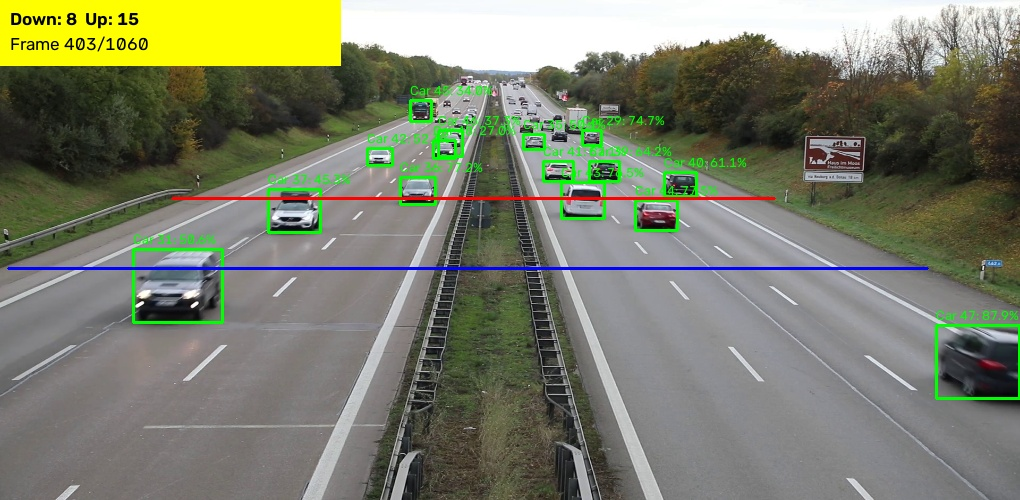

In [1]:
from pathlib import Path
import json
import time
import cv2
import numpy as np
from ultralytics import YOLO
from tracker import Tracker

output_dir = Path("reports")
output_dir.mkdir(exist_ok=True)
model = YOLO("yolov8s.pt")
cap = cv2.VideoCapture("highway.mp4")
assert cap.isOpened(), "Cannot open highway.mp4"
fps = cap.get(cv2.CAP_PROP_FPS)
total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
assert fps > 0
writer = cv2.VideoWriter(str(output_dir / "output.avi"), cv2.VideoWriter_fourcc(*"XVID"), fps, (1020, 500))
assert writer.isOpened(), "Cannot create output video"
tracker = Tracker()
previous = {}
crossings = {}
events = []
finished = set()
count = frames_with_cars = detection_count = 0
confidence_sum = 0.0
best_count = -1
started = time.perf_counter()
try:
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        count += 1
        timestamp = (count - 1) / fps
        frame = cv2.resize(frame, (1020, 500))
        result = model.predict(frame, classes=[2], conf=0.25, verbose=False, device="cpu")[0]
        boxes = result.boxes.xyxy.cpu().numpy().astype(int).tolist()
        confidences = result.boxes.conf.cpu().numpy()
        detection_count += len(boxes)
        confidence_sum += float(confidences.sum())
        frames_with_cars += bool(boxes)
        tracked = tracker.update(boxes)
        for box, confidence in zip(tracked, confidences):
            x1, y1, x2, y2, ident = box
            cy = (y1+y2)/2
            if ident in previous:
                old_y, old_t = previous[ident]
                for name, line in [("red", 198), ("blue", 268)]:
                    if old_y < line <= cy or cy <= line < old_y:
                        crossing_t = old_t + (timestamp-old_t)*(line-old_y)/(cy-old_y)
                        crossings.setdefault(ident, {}).setdefault(name, crossing_t)
                times = crossings.get(ident, {})
                if len(times) == 2 and ident not in finished:
                    elapsed = abs(times["blue"]-times["red"])
                    if elapsed > 0:
                        events.append({"track_id": ident, "direction": "down" if times["blue"] > times["red"] else "up", "speed_kmh": 36/elapsed})
                        finished.add(ident)
            previous[ident] = (cy, timestamp)
            cv2.rectangle(frame, (x1,y1), (x2,y2), (0,255,0), 2)
            cv2.putText(frame, f"Car {ident}: {confidence*100:.1f}%", (x1,max(15,y1-5)), cv2.FONT_HERSHEY_SIMPLEX, .45, (0,255,0), 1)
        down = sum(e["direction"] == "down" for e in events)
        up = len(events)-down
        cv2.line(frame, (172,198), (774,198), (0,0,255), 2)
        cv2.line(frame, (8,268), (927,268), (255,0,0), 2)
        cv2.rectangle(frame, (0,0), (340,65), (0,255,255), -1)
        cv2.putText(frame, f"Down: {down}  Up: {up}", (10,25), cv2.FONT_HERSHEY_SIMPLEX, .6, (0,0,0), 2)
        cv2.putText(frame, f"Frame {count}/{total}", (10,50), cv2.FONT_HERSHEY_SIMPLEX, .6, (0,0,0), 1)
        writer.write(frame)
        if len(boxes) > best_count:
            best_count = len(boxes)
            cv2.imwrite(str(output_dir / "detection_sample.jpg"), frame)
        if count % 100 == 0:
            print(f"Processed {count}/{total} frames", flush=True)
finally:
    cap.release()
    writer.release()
summary = {
    "input": "highway.mp4", "model": "yolov8s.pt", "fps": fps,
    "total_frames": total, "processed_frames": count,
    "completion_percent": 100*count/total,
    "frames_with_cars": frames_with_cars,
    "car_frame_coverage_percent": 100*frames_with_cars/count,
    "car_detections_across_frames": detection_count,
    "mean_detection_confidence_percent": 100*confidence_sum/detection_count if detection_count else None,
    "down_crossings": down, "up_crossings": up,
    "runtime_seconds": time.perf_counter()-started,
    "assumed_line_distance_m": 10,
    "speed_events": events,
    "accuracy_percent": None,
}
(output_dir / "metrics.json").write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))
from IPython.display import Image, display
display(Image(filename=str(output_dir / "detection_sample.jpg")))
